In [7]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import linregress
import os
import glob
import pandas as pd

def load_all_autocorr(base, filename):
    """
    Automatically loads:
        trj/trj_*/{top,bot}/all_autocorr_avgnorm.csv

    Returns:
        data[traj][surface] = DataFrame
    """
    data = {}

    traj_paths = sorted(glob.glob(os.path.join(base, "run_*")))

    for traj in traj_paths:
        
        traj_name = os.path.basename(traj)
        data[traj_name] = {}

        for surf in ["top", "bot"]:
            fpath = os.path.join(traj, surf, filename)

            if os.path.isfile(fpath):
                df = pd.read_csv(fpath)
                data[traj_name][surf] = df
                print(f"Loaded: {fpath}")
            else:
                print(f"Missing: {fpath}")
                data[traj_name][surf] = None

    return data

def build_time_axes(data, dt_fs):
    """
    Build dictionary of time axes in picoseconds,
    with the same keys as the ACF dictionary.

    data[(traj, surface)] = DataFrame with time axis = index

    Returns:
        t_ps[(traj, surface)] = np.array of time points in ps
    """
    t_ps = {}

    for key_1, dict_name in data.items():
        print(key_1)
        t_ps[key_1]={}
        for key_2 , df in dict_name.items():
            n = len(df)
            # t(ps) = frame_index * dt_fs(fs) * 1e-3 (convert fs → ps)
            t_ps[key_1][key_2] = (np.arange(n) * dt_fs) * 1e-3

    return t_ps



In [8]:
######################################################################
# 2. UTILITY FUNCTIONS
######################################################################

def plot_acf(t, C, label=None, logy=True):
    plt.plot(t, C, '-', lw=2, label=label)
    if logy:
        plt.yscale("log")
    plt.xlabel("τ (ps)")
    plt.ylabel("C(τ)")
    if label:
        plt.legend()



def estimate_plateau_excluding_tail(C, exclude_tail_frac, plateau_frac):
    """
    Estimate plateau by:
    - discarding the last exclude_tail_frac of the data entirely
    - averaging the last plateau_frac of the *remaining* part
    """

    N = len(C)
    cut = int((1 - exclude_tail_frac) * N)     # endpoint of usable data

    usable = C[:cut]                           # first (1-excl) portion

    start = int((1 - plateau_frac) * len(usable))  # start of plateau window
    plateau_window = usable[start:]

    p = np.mean(plateau_window)
    return p, usable


def subtract_plateau(C,exclude_tail_frac, plateau_frac):
    p, C_cut = estimate_plateau_excluding_tail(C, exclude_tail_frac, plateau_frac)
    C_corr = C_cut - p
    C_corr /= 1-p
    return C_corr, p


def slope_fit_tau(t, C, t_max, label="",  t_min=0):
    """
    Fit ln(C) = ln(A) - t/tau  on t_min < t < t_max.
    """
    mask = (t >= t_min) & (t <= t_max)
    tt = t[mask]
    CC = C[mask]

    # remove zeros (log undefined)
    mask2 = CC > 0
    tt = tt[mask2]
    CC = CC[mask2]

    lnC = np.log(CC)

    slope, intercept, r, p, stderr = linregress(tt, lnC)
    tau = -1.0 / slope

    print(f"\n=== Fit for {label} ===")
    print(f"τ = {tau:.4f} ps   (slope = {slope:.4f}),  r = {r:.4f}")

    # reconstruct exponential
    C_fit = np.exp(intercept + slope * t)

    # plot
    plt.figure(figsize=(7,5))
    plt.plot(t, C, 'o', ms=3, alpha=0.4, label="data")
    plt.plot(t, C_fit, 'r-', lw=2, label=f"fit τ={tau:.3f} ps")
    plt.yscale("log")
    plt.xlabel("τ (ps)")
    plt.ylabel("C(τ)")
    plt.title(label)
    plt.legend()
    #plt.show()

    return tau, slope, intercept


In [35]:
data_avgnorm = load_all_autocorr("./", "all_autocorr_avgnorm.csv" )
data_normavg = load_all_autocorr("./", "all_autocorr_normavg.csv" )

del data_avgnorm["run_1"]
del data_avgnorm["run_2"]

del data_normavg["run_1"]
del data_normavg["run_2"]

Loaded: ./run_1/top/all_autocorr_avgnorm.csv
Loaded: ./run_1/bot/all_autocorr_avgnorm.csv
Loaded: ./run_2/top/all_autocorr_avgnorm.csv
Loaded: ./run_2/bot/all_autocorr_avgnorm.csv
Loaded: ./run_3/top/all_autocorr_avgnorm.csv
Loaded: ./run_3/bot/all_autocorr_avgnorm.csv
Loaded: ./run_4/top/all_autocorr_avgnorm.csv
Loaded: ./run_4/bot/all_autocorr_avgnorm.csv
Loaded: ./run_5/top/all_autocorr_avgnorm.csv
Loaded: ./run_5/bot/all_autocorr_avgnorm.csv
Loaded: ./run_1/top/all_autocorr_normavg.csv
Loaded: ./run_1/bot/all_autocorr_normavg.csv
Loaded: ./run_2/top/all_autocorr_normavg.csv
Loaded: ./run_2/bot/all_autocorr_normavg.csv
Loaded: ./run_3/top/all_autocorr_normavg.csv
Loaded: ./run_3/bot/all_autocorr_normavg.csv
Loaded: ./run_4/top/all_autocorr_normavg.csv
Loaded: ./run_4/bot/all_autocorr_normavg.csv
Loaded: ./run_5/top/all_autocorr_normavg.csv
Loaded: ./run_5/bot/all_autocorr_normavg.csv


In [36]:
t_ps = build_time_axes(data_avgnorm, dt_fs=500.0)


run_3
run_4
run_5


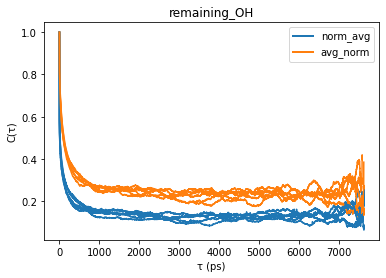

In [37]:
######################################################################
# 3. PLOT A SINGLE SPECIES
######################################################################


species = "remaining_OH"   # EDIT HERE

col = f"C_{species}"

#folder= "trj_3"
#surface="bot"

#plt.plot(t_ps[folder][surface], data_normavg[folder][surface][col], label=f"{species} (normavg)", color="tab:blue")
#plt.plot(t_ps[folder][surface], data_avgnorm[folder][surface][col], label=f"{species} (avgnorm)", color="tab:orange")

for folder in data_normavg.keys():

    for surface in data_normavg[folder].keys():
        #plt.figure() 
        plt.plot(t_ps[folder][surface], data_normavg[folder][surface][col], label=f"{species} (normavg)", color="tab:blue")
        plt.plot(t_ps[folder][surface], data_avgnorm[folder][surface][col], label=f"{species} (avgnorm)", color="tab:orange")


plt.title(species)
#plt.yscale("log")
plt.xlabel("τ (ps)")
plt.ylabel("C(τ)")
# fake lines for legend
line_normavg = plt.Line2D([0], [0], color="tab:blue", lw=2)
line_avgnorm = plt.Line2D([0], [0], color="tab:orange", lw=2)
plt.legend(
    [line_normavg, line_avgnorm],
    ["norm_avg", "avg_norm"],
    loc="best"
)

plt.show()


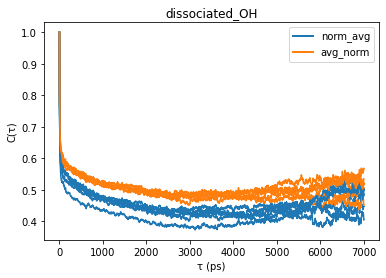

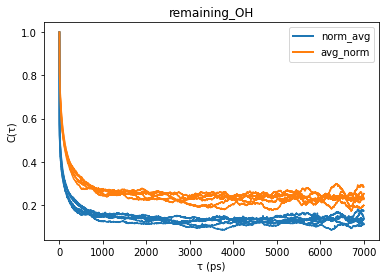

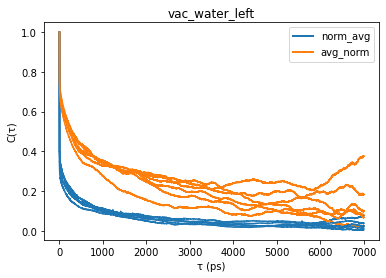

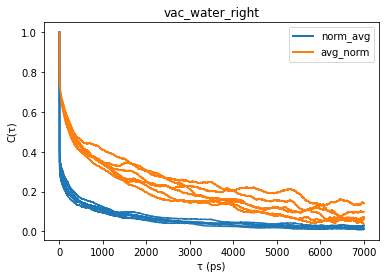

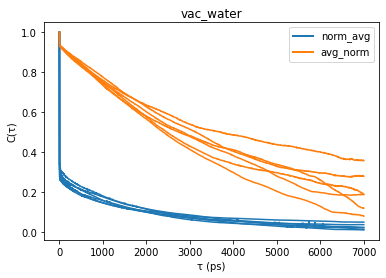

In [67]:
######################################################################
# 3. PLOT ALL SPECIES
######################################################################


plot_list = ["dissociated_OH", "remaining_OH",
             "vac_water_left", "vac_water_right", "vac_water", ]

t_cut_ps = 7000.0  # ps

def make_mask(t_ps, t_cut):
    return t_ps < t_cut

for species in plot_list:

    col = f"C_{species}"



    for folder in data_normavg.keys():
        for surface in data_normavg[folder].keys():
            #plt.figure() 
            mask = make_mask(t_ps[folder][surface], t_cut_ps)
            plt.plot(t_ps[folder][surface][mask], data_normavg[folder][surface][col][mask], label=f"{species} (normavg)", color="tab:blue")
            plt.plot(t_ps[folder][surface][mask], data_avgnorm[folder][surface][col][mask], label=f"{species} (avgnorm)", color="tab:orange")
    plt.title(species)
    #plt.yscale("log")
    plt.xlabel("τ (ps)")
    
    plt.ylabel("C(τ)")
    # fake lines for legend
    line_normavg = plt.Line2D([0], [0], color="tab:blue", lw=2)
    line_avgnorm = plt.Line2D([0], [0], color="tab:orange", lw=2)
    plt.legend(
        [line_normavg, line_avgnorm],
        ["norm_avg", "avg_norm"],
        loc="best"
    )
    #plt.savefig(f"plot_{species}", dpi=200)
    plt.show()


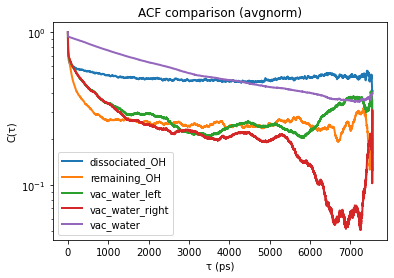

In [43]:
######################################################################
# 5. MULTI-SPECIES COMPARISON
######################################################################

plot_list = ["dissociated_OH", "remaining_OH",
             "vac_water_left", "vac_water_right", "vac_water"]


folder="run_3"
surface="bot"
plt.figure()



for sp in plot_list:
    col = f"C_{sp}"
    plot_acf(t_ps[folder][surface], data_avgnorm[folder][surface][col], label=sp)
   
plt.title("ACF comparison (avgnorm)")
#plt.savefig(f"plot_comparison", dpi=200)
plt.show()


In [15]:

def load_atomic_acf_npz(base="./",
                    ind_name="all_atomic_indicators.npz",
                    acf_name="all_atomic_acfs.npz"):
    """
    Load indicators + acf NPZ files from:
        trj/trj_*/{top,bot}/all_atomic_indicators.npz
        trj/trj_*/{top,bot}/all_atomic_acfs.npz

    Returns:
        atomic_ind[(traj, surface)] = dict of dicts
        atomic_acf[(traj, surface)] = dict of dicts
    """
    atomic_ind = {}
    atomic_acf = {}

    traj_dirs = sorted(glob.glob(os.path.join(base, "trj_*")))

    for traj in traj_dirs:
        traj_name = os.path.basename(traj)

        for surface in ["top", "bot"]:
            key = (traj_name, surface)

       
            # =============================
            #       ACFs
            # =============================
            acf_path = os.path.join(traj, surface, acf_name)
            if os.path.isfile(acf_path):
                try:
                    arr = np.load(acf_path, allow_pickle=True)["atomic_acfs"]
                    atomic_acf[key] = arr.item() if hasattr(arr, "item") else arr
                    print(f"Loaded ACFs: {acf_path}")
                except Exception as e:
                    print(f"Error loading {acf_path}: {e}")
                    atomic_acf[key] = None
            else:
                print(f"Missing ACFs: {acf_path}")
                atomic_acf[key] = None

    return atomic_acf



def load_atomic_ind_npz(base="./",
                    ind_name="all_atomic_indicators.npz",
                    acf_name="all_atomic_acfs.npz"):
    """
    Load indicators + acf NPZ files from:
        trj/trj_*/{top,bot}/all_atomic_indicators.npz
        trj/trj_*/{top,bot}/all_atomic_acfs.npz

    Returns:
        atomic_ind[(traj, surface)] = dict of dicts
        atomic_acf[(traj, surface)] = dict of dicts
    """
    atomic_ind = {}
    atomic_acf = {}

    traj_dirs = sorted(glob.glob(os.path.join(base, "trj_*")))

    for traj in traj_dirs:
        traj_name = os.path.basename(traj)

        for surface in ["top", "bot"]:
            key = (traj_name, surface)

            # =============================
            #       Indicators
            # =============================
            ind_path = os.path.join(traj, surface, ind_name)
            if os.path.isfile(ind_path):
                try:
                    arr = np.load(ind_path, allow_pickle=True)["atomic_indicators"]
                    atomic_ind[key] = arr.item() if hasattr(arr, "item") else arr
                    print(f"Loaded indicators: {ind_path}")
                except Exception as e:
                    print(f"Error loading {ind_path}: {e}")
                    atomic_ind[key] = None
            else:
                print(f"Missing indicators: {ind_path}")
                atomic_ind[key] = None

    return atomic_ind



In [16]:
 atomic_acf = load_atomic_acf_npz()



#del atomic_ind[('run_1', 'top')]
#del atomic_ind[('run_1', 'bot')]
#del atomic_ind[('run_2', 'top')]
#del atomic_ind[('run_2', 'bot')]

del atomic_acf[('run_1', 'top')]
del atomic_acf[('run_1', 'bot')]
del atomic_acf[('run_2', 'top')]
del atomic_acf[('run_2', 'bot')]



Missing ACFs: ./trj_tar/top/all_atomic_acfs.npz
Missing ACFs: ./trj_tar/bot/all_atomic_acfs.npz


KeyError: ('run_1', 'top')

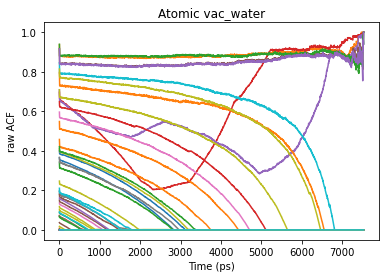

In [66]:
spec= "vac_water"
# Access the ACF for the same atom
acf_vec = atomic_acf[("run_3", "bot")][spec]
for part in acf_vec.keys():
    plt.plot(np.arange(len(acf_vec[part]))*0.5,  acf_vec[part])

plt.title(f"Atomic {spec}")
plt.ylabel("raw ACF")
plt.xlabel("Time (ps)")
#plt.savefig(f"plot_C_atomic_{spec}", dpi=200)

In [55]:
def sum_atomic_acfs(acf_dict, species):
    """
    acf_dict[(traj, surface)] = {species: {atom: acf_array}}

    Returns:
        t_common_length  – the length of the overlapped ACF region (int)
        C_sum_norm       – normalized sum C_total(t)/C_total(0)
        n_contributing   – number of atoms contributing
    """
    # find minimal length of arrays across all traj/surf/atoms
    min_len = None

    for key in acf_dict:
        
        species_acfs = acf_dict[key].get(species, {})
        for atom, C in species_acfs.items():
            L = len(C)
            if min_len is None or L < min_len:
                min_len = L

    if min_len is None:
        print(f"No ACFs found for species {species}")
        return None, None, 0

    # sum the ACFs over the common region
    C_sum = np.zeros(min_len)
    n_eff = 0

    for key in acf_dict:
        species_acfs = acf_dict[key].get(species, {})
        for atom, C in species_acfs.items():
            C_sum += C[:min_len]
            n_eff += 1

    if n_eff == 0:
        print(f"No atoms found for species {species}")
        return None, None, 0

    # normalized global ACF
    C_sum_norm = C_sum / C_sum[0]

    return min_len, C_sum_norm, n_eff


In [56]:
plot_list = ["dissociated_OH", "remaining_OH",
             "vac_water_left", "vac_water_right", "vac_water"]


C_total={}
for species in plot_list:
    min_len, C_tot, n = sum_atomic_acfs(atomic_acf, species)
    C_total[species]=C_tot
    print(species)
    print("atoms contributing:", n)
    print("common length:", min_len)


dissociated_OH
atoms contributing: 201
common length: 15083
remaining_OH
atoms contributing: 601
common length: 15083
vac_water_left
atoms contributing: 477
common length: 15083
vac_water_right
atoms contributing: 481
common length: 15083
vac_water
atoms contributing: 791
common length: 15083


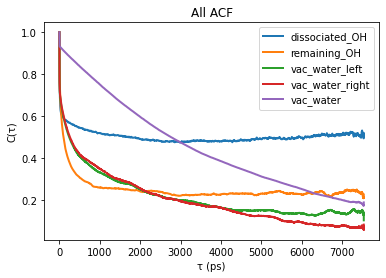

In [60]:
for species in plot_list:
    plot_acf(np.arange(len(C_total[species]))*0.5,C_total[species], label=species, logy=False)
    
plt.title("All ACF")
#plt.savefig("plot_all_ACF",dpi=300)

In [1]:
exclude_tail_frac=0.7
plateau_frac=0.3
species="dissociated_OH"
C_delta, plateu =subtract_plateau(C_total[species],exclude_tail_frac, plateau_frac)

t=np.arange(len(C_delta))*0.5

tau, slope, intercept= slope_fit_tau(t,C_delta, t_max=1800, label="",  t_min=100)
plt.title(f"Fit tau {species}")
#plt.savefig(f"fit_{species}")
plt.show()

NameError: name 'subtract_plateau' is not defined


=== Fit for  ===
τ = 516.0915 ps   (slope = -0.0019),  r = -0.9712


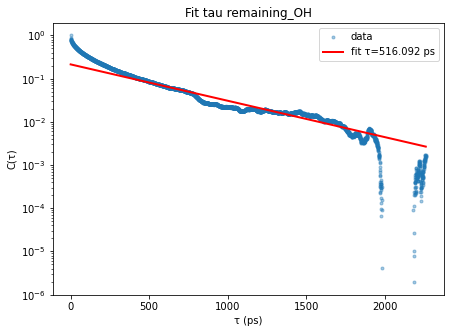

In [ ]:
species="remaining_OH"
exclude_tail_frac=0.7
plateau_frac=0.2

C_delta, plateu =subtract_plateau(C_total[species],exclude_tail_frac, plateau_frac)

t=np.arange(len(C_delta))*0.5

tau, slope, intercept= slope_fit_tau(t,C_delta, t_max=1750, label="",  t_min=200)
plt.title(f"Fit tau {species}")
#plt.savefig(f"fit_{species}")
plt.show()


=== Fit for  ===
τ = 1414.9814 ps   (slope = -0.0007),  r = -0.9858


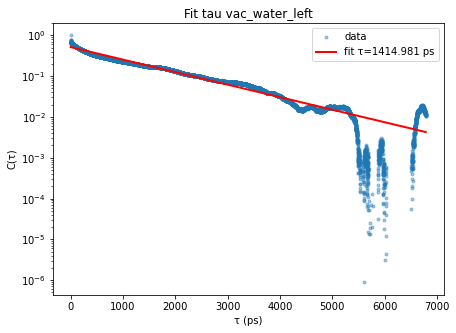

In [ ]:
species="vac_water_left"
exclude_tail_frac=0.1
plateau_frac=0.2

C_delta, plateu =subtract_plateau(C_total[species],exclude_tail_frac, plateau_frac)

t=np.arange(len(C_delta))*0.5

tau, slope, intercept= slope_fit_tau(t,C_delta, t_max=5000, label="",  t_min=500)
plt.title(f"Fit tau {species}")
#plt.savefig(f"fit_{species}")
plt.show()


=== Fit for  ===
τ = 2369.2279 ps   (slope = -0.0004),  r = -0.9955


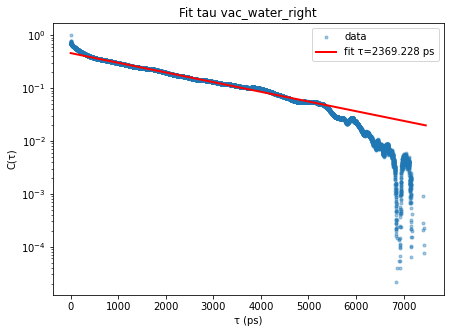

In [166]:
species="vac_water_right"
exclude_tail_frac=0.01
plateau_frac=0.1

C_delta, plateu =subtract_plateau(C_total[species],exclude_tail_frac, plateau_frac)

t=np.arange(len(C_delta))*0.5

tau, slope, intercept= slope_fit_tau(t,C_delta, t_max=5500, label="",  t_min=500)
plt.title(f"Fit tau {species}")
#plt.savefig(f"fit_{species}")
plt.show()

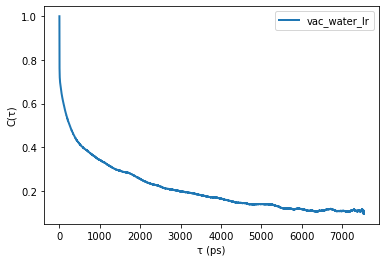

In [ ]:
C_vac_wat=1/2*(C_total["vac_water_left"]+C_total["vac_water_right"])

plot_acf(np.arange(len(C_vac_wat))*0.5,C_vac_wat, label="vac_water_lr", logy=False)


plt.show()


=== Fit for vac_water_lr ===
τ = 1978.3358 ps   (slope = -0.0005),  r = -0.9956


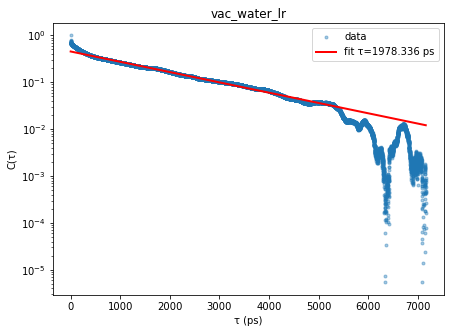

In [170]:


exclude_tail_frac=0.05
plateau_frac=0.01

C_delta, plateu =subtract_plateau(C_vac_wat,exclude_tail_frac, plateau_frac)

t=np.arange(len(C_delta))*0.5

tau, slope, intercept= slope_fit_tau(t,C_delta, t_max=5500, label="vac_water_lr",  t_min=500)

#plt.savefig("fit_vac_water_lr")